# Logboek Casus A
## Casus Dynamic Modelling (ODEs)
Door: Fleur Luten  
Datum: 16-11-2026 t/m 26-11-2026

We volgen de workshops 1 t/m 4 van de casus Dynamic Modelling (ODE's) die voor ons beschikbaar zijn gesteld bij deze opdracht in Brightspace van de module Modelleren van Kanker in leerjaar 3 van de opleiding Bio-Informatica aan de Hanze.

In [11]:
# Alle imports voor dit logboek
import pandas as pd
import matplotlib.pyplot as plt

import random

# Zorgen dat dezelfde willekeurige reeks opnieuw gebruikt wordt (vanwege random search)
random.seed(42)

from tumor_models.models import mendelsohn_growth

from tumor_models.solvers import euler_solver
from tumor_models.euler_models import EULER_MODELS

from tumor_models.optimization import bereken_mse, random_search

### 16-11-2026

We zijn begonnen met casus A en hebben de opdracht die hier bij hoort doorgelezen. De git repository is aangemaakt: https://github.com/FleurLuten/ModellerenVanKankerCasusA en een paar nodige bestanden zijn alvast aangemaakt, zoals de logboeken en de README. Ik ben begonnen met het zoeken naar een geschikte dataset om deze opdracht mee uit te voeren. De dataset die hoort bij dit onderzoek: https://causeweb.org/tshs/tumor-growth/ is denk ik wel bruikbaar, maar dit ga ik woensdag (in de eerstvolgende les) verder overleggen en uitzoeken. We moeten ook nog een duidelijke taakverdeling/planning gaan maken. 

### 18-11-2026

Vandaag heb ik vooral de dataset doorgenomen die ik op 16-11-2026 genoemd had. Dit is een dataset over de tumorgroei van tumoren in verschillende groepen muizen. Ik heb ook een scatterplot gemaakt van deze data, die code staat nu nog in "data_inlezen.py", maar dit is vooral een test, dus daarom zet ik deze code ook even hier neer:

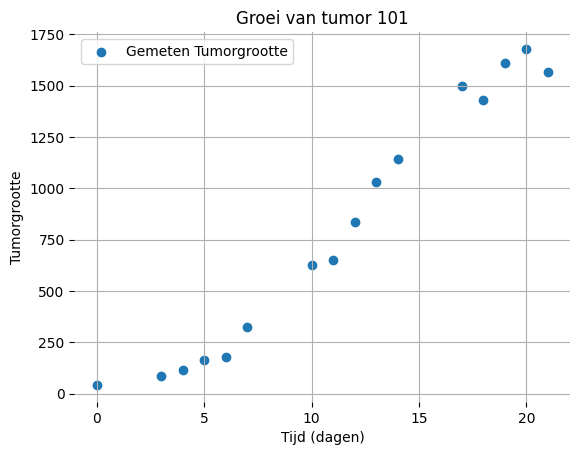

In [12]:
data = pd.read_excel("../Data/tumorgrowth.xlsx", sheet_name="AnalysisData")

tumor_id = 101

tumor = data[data["ID"] == tumor_id]
tumor = tumor.sort_values(by="Day")

plt.scatter(tumor["Day"], tumor["Size"], label="Gemeten Tumorgrootte")

plt.xlabel("Tijd (dagen)")
plt.ylabel("Tumorgrootte")
plt.title(f"Groei van tumor {tumor_id}")

plt.legend()
plt.grid(True); plt.box(False)

plt.show()


Het tumor_id kan aangepast worden op basis van welke tumorgroei te wil zien.  
Het plan is nu dat we allebei een van de "simpelere" formules gaan uitwerken op deze dataset volgens workshop 1 en workshop 2. Ik ga die van "Mendelsohn groei" uitwerken. In de directory: "tumor_modellen" heb ik nu de bestanden aangemaakt om hier aan te werken. Ik werk hier voor op een aparte branch voor deze formule.  
De Mendelsohn groei formule berekent de exponentiële groei waarbij de groeisnelheid evenredig is met een macht van de huidige omvang: dV/dt = c * V^d  
- V: Het volume van de tumor op dat tijdstip t.
- c: De groeiconstante: Deze bepaalt hoe snel de groei in absolute zin verloopt.
- d: De allometrische exponent. Deze parameter geeft aan welk deel van het volume actief bijdraagt aan de groei.  

Dit moet ik nu gaan omzetten in een functie, zodat deze kan uitgevoerd worden op onze dataset. Dit was makkelijker dan wat ik had verwacht, omdat je de formule gewoon in de return statement van de functie kan zetten, dan kan je natuurlijk later de waardes invullen bij het aanroepen van de functie. Zie models.py voor de functie. Ik heb er voor gekozen om de Euler methode ook uit te werken in solvers.py. Dit is de test code hier voor met een paar random waardes (om dus te testen of het werkt):

In [13]:
times, volumes = euler_solver(
    model=mendelsohn_growth,
    V0=20,
    t_start=0,
    t_end=2,
    dt=0.5,
    parameters=(0.1, 2)
)

print(times)
print(volumes)


[0, 0.5, 1.0, 1.5, 2.0]
[20, 40.0, 120.0, 840.0, 36120.0]


De test lijkt te werken, dus ik ga verder door het te testen op de dataset. Hierbij gebruik ik een deel van de code die ik eerder al had benoemd uit "data_inlezen.py" dat bestand is hierdoor echt overbodig, ook omdat ik het eerst had geschreven om alleen te kijken naar hoe de dataset er een beetje uit ziet, dus dit bestand heb ik nu verwijderd. De parameters die ik nu heb ingevuld geven alleen een rechte lijn (iets van y = 0). Ik hoop dat dit aan deze parameters ligt en niet aan dat de code niet klopt, dus die waardes ga ik nu eerst even een paar keer aanpassen om te kijken of het wat veranderd (heb nu c = 0.00001 en d = 2). Het laten bepalen van welke waardes hier voor het beste zijn komt volgens mij ook in een latere workshop, maar het lijkt mij dat ik zelf ook al iets betere resultaten kan krijgen door zelf wat dingen te testen. Met c = 0000.1 en d = 3 of met c = 0.001 en d = 2 zie ik wel iets van een curve op het einde van de lijn staan, maar nog lang niet goed genoeg. Ik krijg wel deze foutmelding: "OverflowError: (34, 'Result too large')" wanneer ik sommige aanpassingen doe. Ik laat het voor nu staan op c = 0.001 en d = 2, omdat je hier in wel iets van een curve kan zien. Hier ga ik later dan mee verder wanneer we op een verdere stap zijn.  
Dit is de code waar ik het over had: 

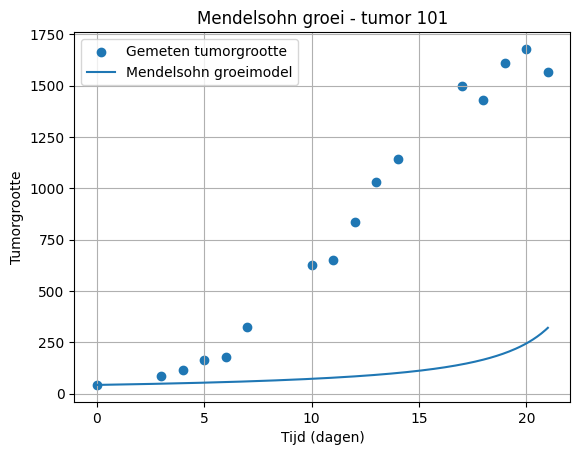

In [14]:
# Dataset inlezen
data = pd.read_excel("../Data/tumorgrowth.xlsx", sheet_name="AnalysisData")

# Een individuele tumor selecteren
tumor_id = 101

tumor = data[data["ID"] == tumor_id]
tumor = tumor.sort_values(by="Day")

# Beginvolume en meetperiode bepalen
V0 = float(tumor["Size"].iloc[0])
t_start = float(tumor["Day"].iloc[0])
t_end = float(tumor["Day"].iloc[-1])

# Parameters instellen
c = 0.001
d = 2

# Euler-methode uitvoeren
times, volumes = euler_solver(
    model=mendelsohn_growth,
    V0=V0,
    t_start=t_start,
    t_end=t_end,
    dt=0.1,
    parameters=(c, d)
)

# Gemeten gegevens en voorspelling plotten
plt.scatter(
    tumor["Day"],
    tumor["Size"],
    label="Gemeten tumorgrootte"
)

plt.plot(
    times,
    volumes,
    label="Mendelsohn groeimodel"
)

plt.xlabel("Tijd (dagen)")
plt.ylabel("Tumorgrootte")
plt.title(f"Mendelsohn groei - tumor {tumor_id}")

plt.legend()
plt.grid(True)
plt.show()


### 19-11-2026
Ik wil vandaag de andere formules die door Vincent zijn geschreven ook uitvoerbaar krijgen met de Euler methode, dus even testen wat ik daar voor extra moet doen en hoe dat er dan uit ziet. 
Voor het aanpassen op andere modellen: model naam aanpassen, parameter aantal/nodige parameters aanpassen.  
We hebben afgesproken dat ik verder ga volgens de workshops met de modellen/functies die we al hebben en de Euler methode en Vincent gaat datzelfde doen voor de Heuns methode, dit willen we voor maandag afhebben, zodat we maandag in de les de README kunnen schrijven en alles afmaken. Ik ga met mijn onderdeel hier van dit weekend verder.


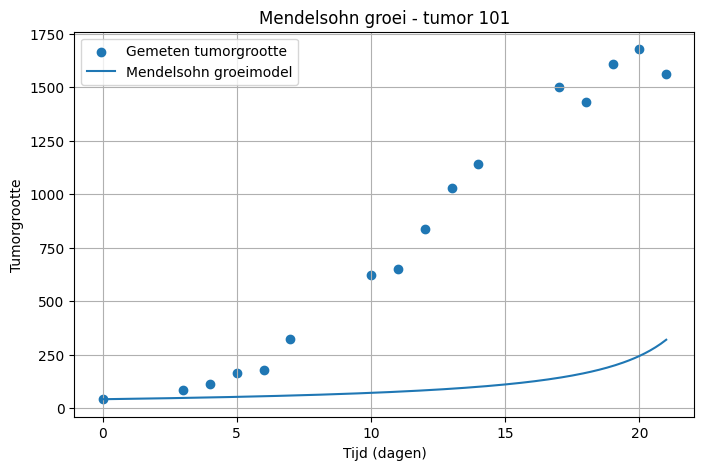

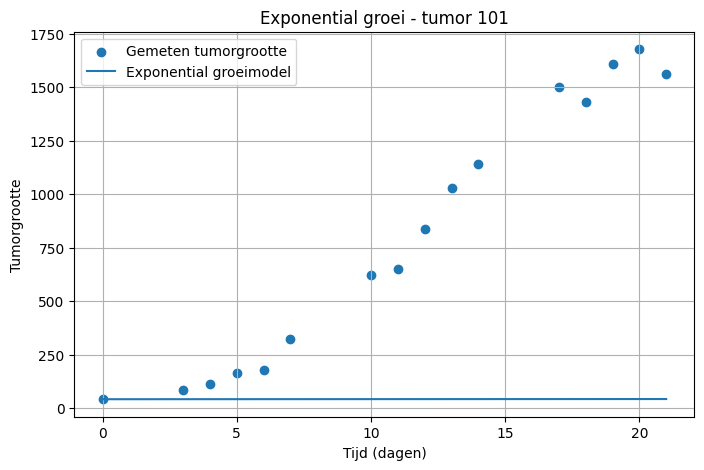

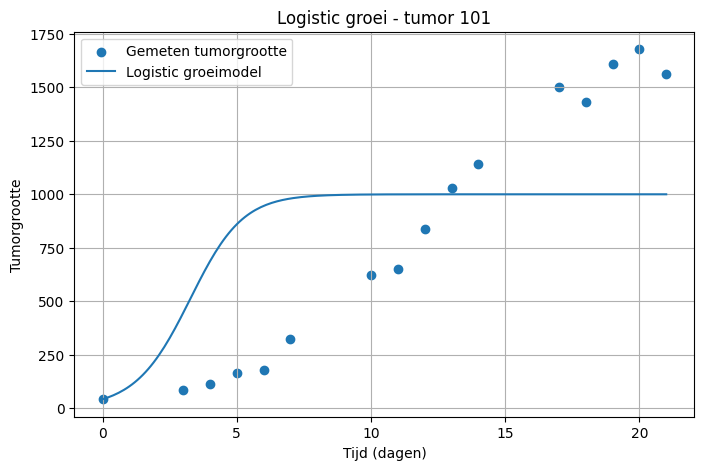

([0.0,
  0.1,
  0.2,
  0.30000000000000004,
  0.4,
  0.5,
  0.6,
  0.7,
  0.7999999999999999,
  0.8999999999999999,
  0.9999999999999999,
  1.0999999999999999,
  1.2,
  1.3,
  1.4000000000000001,
  1.5000000000000002,
  1.6000000000000003,
  1.7000000000000004,
  1.8000000000000005,
  1.9000000000000006,
  2.0000000000000004,
  2.1000000000000005,
  2.2000000000000006,
  2.3000000000000007,
  2.400000000000001,
  2.500000000000001,
  2.600000000000001,
  2.700000000000001,
  2.800000000000001,
  2.9000000000000012,
  3.0000000000000013,
  3.1000000000000014,
  3.2000000000000015,
  3.3000000000000016,
  3.4000000000000017,
  3.5000000000000018,
  3.600000000000002,
  3.700000000000002,
  3.800000000000002,
  3.900000000000002,
  4.000000000000002,
  4.100000000000001,
  4.200000000000001,
  4.300000000000001,
  4.4,
  4.5,
  4.6,
  4.699999999999999,
  4.799999999999999,
  4.899999999999999,
  4.999999999999998,
  5.099999999999998,
  5.1999999999999975,
  5.299999999999997,
  5.399999

In [15]:
# Dataset inlezen
data = pd.read_excel(
    "../Data/tumorgrowth.xlsx",
    sheet_name="AnalysisData"
)

def voer_euler_uit(tumor_id, model_naam, parameters, dt=0.1):

    # Individuele tumor selecteren
    tumor = data[data["ID"] == tumor_id].sort_values(by="Day")

    if tumor.empty:
        raise ValueError(f"Geen gegevens gevonden voor tumor {tumor_id}.")

    # Beginvolume en meetperiode bepalen
    V0 = float(tumor["Size"].iloc[0])
    t_start = float(tumor["Day"].iloc[0])
    t_end = float(tumor["Day"].iloc[-1])

    # Model selecteren
    model = EULER_MODELS[model_naam]

    # Euler-methode uitvoeren
    times, volumes = euler_solver(
        model=model,
        V0=V0,
        t_start=t_start,
        t_end=t_end,
        dt=dt,
        parameters=parameters
    )

    # Gemeten gegevens en voorspelling plotten
    plt.figure(figsize=(8, 5))

    plt.scatter(
        tumor["Day"],
        tumor["Size"],
        label="Gemeten tumorgrootte"
    )

    plt.plot(
        times,
        volumes,
        label=f"{model_naam} groeimodel"
    )

    plt.xlabel("Tijd (dagen)")
    plt.ylabel("Tumorgrootte")
    plt.title(f"{model_naam} groei - tumor {tumor_id}")

    plt.legend()
    plt.grid(True)
    plt.show()

    return times, volumes

# Paar tests voor uitvoeren:

# Mendelsohn
voer_euler_uit(
    tumor_id=101,
    model_naam="Mendelsohn",
    parameters=(0.001, 2)
)

# Exponential
voer_euler_uit(
    tumor_id=101,
    model_naam="Exponential",
    parameters=(0.001,)
)

# Logistic
voer_euler_uit(
    tumor_id=101,
    model_naam="Logistic",
    parameters=(0.001, 1000)
)




### 22-11-2026
Vandaag ga ik bezig met de optimalisatie (workshop 3) en daarna ga ik de modelvergelijking doen (workshop 4). 

Ik ben begonnen met de "bereken_mse" functie in optimazation.py om de MSE te berekenen, De Mean Squared Error is het gemiddelde van de gekwadrateerde verschillen tussen voorspelde waarden en werkelijke waarden. Grote afwijkingen wegen hierbij zwaarder mee.  
bron: https://dodona.be/nl/activities/2069146514/  
Ik heb voor deze functie ook een controle op extreem grote waardes toegevoegd, omdat ik een stackoverflow error kreeg, die hier mee gefixt is.

Hierna ben ik verder gegaan met het onderdeel van Monte Carlo/Random search in optimization.py. Deze methode is om automatisch naar de betere waardes voor de parameters van de groeimodellen te zoeken. Hierbij wordt steeds opnieuw de MSE berekent, als de nieuwe MSE lager is dan de vorige worden de nieuwe parameters bewaard. Ik heb het nu ingesteld dat het stopt wanneer er 1000 pogingen gedaan zijn waarbij geen verbetering is gevonden, de best gevonden parameters en de MSE hier bij worden teruggegeven door de functie.

Voordat ik verder ga heb ik dit getest op 1 model (het mendelsohn model) om te controleren of het werkt. 

De code hier onder is dus voor het mendelsohn model, deze heeft parameters c en d, hiervoor heb ik de stapwaarden, stapgroottes (hoeveel parameterwaarden tijdens de random search willekeurig kunnen veranderen) en grenzen (zodat de parameters binnen bereik blijven) ingesteld.  
dit kwam er uit:  
Beste parameters:  
{'c': 0.006230479101997811, 'd': 1.6438983041769593}  
Beste MSE:  
407083.80079363246  
De grafiek liet alleen nog steeds zien dat het Mendelsohn-model niet overal goed aansluit op de metingen. In de grafiek is te zien dat de voorspelde groei aan het einde sterk toeneemt. Dit laat zien dat de optimalisatie de parameterwaarden kan verbeteren, maar dat het gekozen groeimodel waarschijnlijk niet de beste beschrijving van deze tumor is.

Beste parameters:
{'c': 0.006230479101997811, 'd': 1.6438983041769593}
Beste MSE:
407083.80079363246


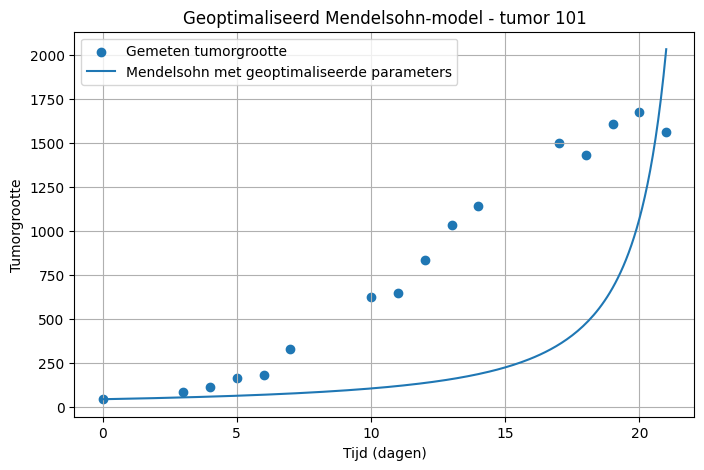

In [5]:
# Tumor selecteren
tumor_id = 101

tumor = data[data["ID"] == tumor_id].sort_values(by="Day")

# Meetgegevens ophalen
meetdagen = tumor["Day"].to_numpy(dtype=float)
meetwaarden = tumor["Size"].to_numpy(dtype=float)

# Beginwaarden
V0 = meetwaarden[0]
t_start = meetdagen[0]

# Model selecteren
model = EULER_MODELS["Mendelsohn"]

# Startwaarden voor de parameters
start_parameters = {
    "c": 0.001,
    "d": 2.0
}

# Stapgroottes voor de willekeurige veranderingen
stapgroottes = {
    "c": 0.0001,
    "d": 0.1
}

# Grenzen voor de parameters
grenzen = {
    "c": (0.000001, 0.1),
    "d": (0.1, 3.0)
}

# Random Search uitvoeren
beste_parameters, beste_mse = random_search(
    model=model,
    start_parameters=start_parameters,
    stapgroottes=stapgroottes,
    V0=V0,
    t_start=t_start,
    meetdagen=meetdagen,
    meetwaarden=meetwaarden,
    dt=0.1,
    max_tries=1000,
    grenzen=grenzen
)

print("Beste parameters:")
print(beste_parameters)

print("Beste MSE:")
print(beste_mse)

# Euler uitvoeren met de geoptimaliseerde parameters
times, volumes = euler_solver(
    model=model,
    V0=V0,
    t_start=t_start,
    t_end=max(meetdagen),
    dt=0.1,
    parameters=tuple(beste_parameters.values())
)

# Grafiek maken
plt.figure(figsize=(8, 5))

plt.scatter(
    meetdagen,
    meetwaarden,
    label="Gemeten tumorgrootte"
)

plt.plot(
    times,
    volumes,
    label="Mendelsohn met geoptimaliseerde parameters"
)

plt.xlabel("Tijd (dagen)")
plt.ylabel("Tumorgrootte")
plt.title(f"Geoptimaliseerd Mendelsohn-model - tumor {tumor_id}")

plt.legend()
plt.grid(True)
plt.show()

Ookal is dit dus niet het beste resultaat ga ik wel verder met de andere modellen, omdat het me lijkt dat een van die dan betere resultaten gaat geven. Ik heb voor deze de verschillende startwaardes, stappen en grenzen hier onder als eerste opgeschreven in een dictionary, zodat ik deze later makkelijker kan gebruiken.


In [6]:
# Instellingen voor de Random Search per model

model_instellingen = {
    "Mendelsohn": {
        "start": {"c": 0.001, "d": 2.0},
        "stappen": {"c": 0.0001, "d": 0.1},
        "grenzen": {"c": (0.000001, 0.1), "d": (0.1, 3.0)}
    },

    "Exponential": {
        "start": {"c": 0.001},
        "stappen": {"c": 0.0001},
        "grenzen": {"c": (0.000001, 0.1)}
    },

    "Linear": {
        "start": {"c": 0.1},
        "stappen": {"c": 0.01},
        "grenzen": {"c": (0.000001, 10.0)}
    },

    "Exponential smooth": {
        "start": {"c": 0.001, "Vmax": 1000},
        "stappen": {"c": 0.0001, "Vmax": 10},
        "grenzen": {"c": (0.000001, 0.1), "Vmax": (100, 10000)}
    },

    "Logistic": {
        "start": {"c": 0.000001, "Vmax": 1000},
        "stappen": {"c": 0.0000001, "Vmax": 10},
        "grenzen": {"c": (0.00000001, 0.001), "Vmax": (100, 10000)}
    },

    "Montroll": {
        "start": {"c": 0.000001, "d": 1.0, "Vmax": 1000},
        "stappen": {"c": 0.0000001, "d": 0.1, "Vmax": 10},
        "grenzen": {"c": (0.000000001, 0.001), "d": (0.1, 3.0), "Vmax": (100, 10000)}
    },

    "Allee effect": {
        "start": {"c": 0.000001, "Vmin": 10, "Vmax": 1000},
        "stappen": {"c": 0.0000001, "Vmin": 1, "Vmax": 10},
        "grenzen": {"c": (0.000000001, 0.001), "Vmin": (0, 100), "Vmax": (100, 10000)}
    }
}

Om de optimalisatie voor alle groeimodellen uit te voeren, heb ik de functie optimaliseer_model gemaakt. Deze functie selecteert de gekozen tumor en haalt automatisch de bijbehorende meetgegevens op. Vervolgens worden de instellingen en de groeiformule van het gekozen model gebruikt. De random search wordt dan uitgevoerd en de beste parameters/MSE wordt teruggegeven.  
Met een for loop heb ik vervolgens al deze modellen laten optimaliseren. Hier heb ik een tabel van gemaakt, zodat je in 1 oogopslag de resultaten kan zien.  
Uit de resultaten blijkt dat Logistic, Montroll en Allee effect de laagste MSE hebben. Mendelsohn, Exponential en Linear hebben een redelijk hogere MSE. Dit betekent dat de voorspellingen van Logistic, Montroll en Allee effect dichter bij de gemeten tumorgroottes liggen. Dit is ook meteen een mogelijke verklaring voor dat ik eerder tegen het probleem aan liep dat het mendelsohn model niet een super mooie lijn liet zien, deze heeft in verhouding een veel hogere MSE en wijkt dus meer af van de realiteit.

In [7]:
def optimaliseer_model(model_naam, tumor_id):

    # Tumor selecteren
    tumor = data[data["ID"] == tumor_id].sort_values(by="Day")

    meetdagen = tumor["Day"].to_numpy(dtype=float)
    meetwaarden = tumor["Size"].to_numpy(dtype=float)

    V0 = meetwaarden[0]
    t_start = meetdagen[0]

    # Instellingen ophalen
    instellingen = model_instellingen[model_naam]

    # Model ophalen
    model = EULER_MODELS[model_naam]

    # Random Search uitvoeren
    beste_parameters, beste_mse = random_search(
        model=model,
        start_parameters=instellingen["start"],
        stapgroottes=instellingen["stappen"],
        V0=V0,
        t_start=t_start,
        meetdagen=meetdagen,
        meetwaarden=meetwaarden,
        dt=0.1,
        max_tries=1000,
        grenzen=instellingen["grenzen"]
    )

    print(f"Model: {model_naam}")
    print("Beste parameters:", beste_parameters)
    print("Beste MSE:", beste_mse)

    return beste_parameters, beste_mse


resultaten = []

for model_naam in EULER_MODELS:

    parameters, mse = optimaliseer_model(
        model_naam=model_naam,
        tumor_id=101
    )

    resultaten.append({
        "Model": model_naam,
        "Parameters": parameters,
        "MSE": mse
    })

resultaten_df = pd.DataFrame(resultaten)

display(resultaten_df)

Model: Mendelsohn
Beste parameters: {'c': 0.00998547910259252, 'd': 1.5497807798388217}
Beste MSE: 359967.4848039829
Model: Exponential
Beste parameters: {'c': 0.09999999250706981}
Beste MSE: 687119.4186108877
Model: Linear
Beste parameters: {'c': 9.999969353319605}
Beste MSE: 715606.7171274284
Model: Exponential smooth
Beste parameters: {'c': 0.00788101446175652, 'Vmax': 9999.932442851432}
Beste MSE: 33686.82796787832
Model: Logistic
Beste parameters: {'c': 0.00017613342187720006, 'Vmax': 1753.591373676401}
Beste MSE: 2286.723951015937
Model: Montroll
Beste parameters: {'c': 1.043905031896255e-06, 'd': 1.6853784854024931, 'Vmax': 1641.6731980458471}
Beste MSE: 2074.3539574419524
Model: Allee effect
Beste parameters: {'c': 0.00015564769057012801, 'Vmin': 0.019897878828053404, 'Vmax': 1886.3032052426265}
Beste MSE: 3932.888596319728


,Model,Parameters,MSE
0,Mendelsohn,"{'c': 0.00998547910259252, 'd': 1.549780779838...",359967.484804
1,Exponential,{'c': 0.09999999250706981},687119.418611
2,Linear,{'c': 9.999969353319605},715606.717127
3,Exponential smooth,"{'c': 0.00788101446175652, 'Vmax': 9999.932442...",33686.827968
4,Logistic,"{'c': 0.00017613342187720006, 'Vmax': 1753.591...",2286.723951
5,Montroll,"{'c': 1.043905031896255e-06, 'd': 1.6853784854...",2074.353957
6,Allee effect,"{'c': 0.00015564769057012801, 'Vmin': 0.019897...",3932.888596


Nu ik dit heb gedaan wil ik alles nog plotten, ik ga dit in 1 grafiek plotten, zodat het verschil tussen de verschillende modellen beter te zien is.  
In de grafiek is te zien dat de modellen verschillende groeicurves hebben. Vooral Logistic, Montroll en Allee effect sluiten best goed aan op de gemeten waarden. Dit komt overeen met de MSE-resultaten, waarin deze drie modellen ook de laagste waarden hadden.
Als ik later nog genoeg tijd heb wil ik het liefste nog iets meer kijken naar de grenzen en dingen die ik heb ingesteld voor de verschillende modellen, om zeker te weten dat dit de beste resultaten zijn voor alle modellen en niet dat sommige veel beter kunnen zijn als ik dingen daar in aan pas, maar voor nu ga ik eerst verder met de modelvergelijking van workshop 4.

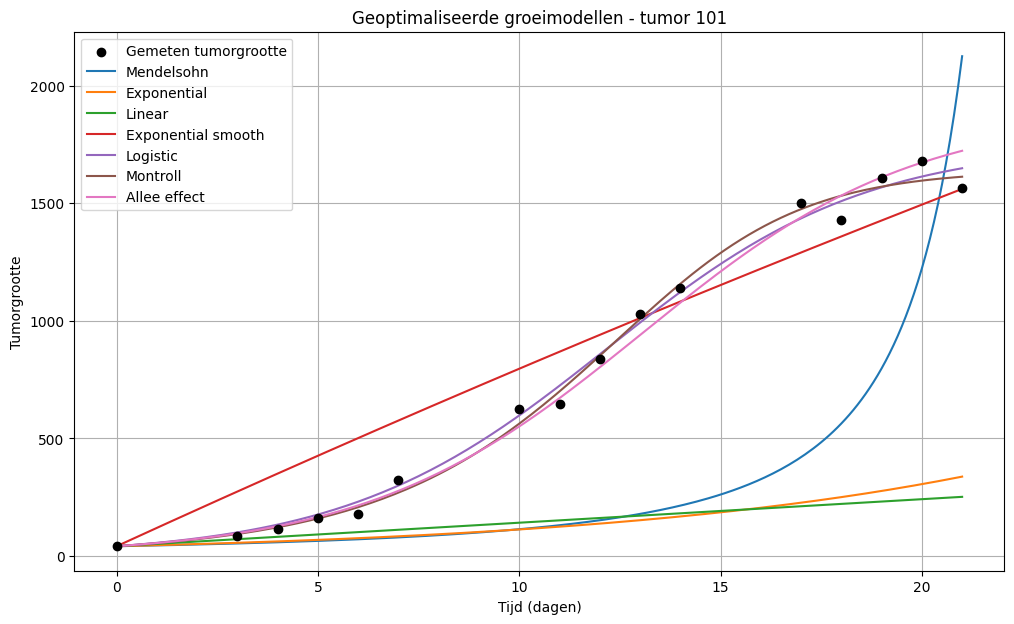

In [8]:
# Tumor selecteren
tumor_id = 101
tumor = data[data["ID"] == tumor_id].sort_values(by="Day")

meetdagen = tumor["Day"].to_numpy(dtype=float)
meetwaarden = tumor["Size"].to_numpy(dtype=float)

V0 = meetwaarden[0]
t_start = meetdagen[0]
t_end = meetdagen[-1]

# Grafiek maken
plt.figure(figsize=(12, 7))

# Gemeten tumorgroottes plotten
plt.scatter(
    meetdagen,
    meetwaarden,
    color="black",
    label="Gemeten tumorgrootte",
    zorder=10
)

# Elk geoptimaliseerd model plotten
for resultaat in resultaten:

    model_naam = resultaat["Model"]
    parameters = resultaat["Parameters"]

    model = EULER_MODELS[model_naam]

    times, volumes = euler_solver(
        model=model,
        V0=V0,
        t_start=t_start,
        t_end=t_end,
        dt=0.1,
        parameters=tuple(parameters.values())
    )

    plt.plot(
        times,
        volumes,
        label=model_naam
    )

plt.xlabel("Tijd (dagen)")
plt.ylabel("Tumorgrootte")
plt.title(f"Geoptimaliseerde groeimodellen - tumor {tumor_id}")

plt.legend()
plt.grid(True)
plt.show()
